# RQ5: Robustness to operator phrasing

Rebuilds the numbers behind Fig. 7 and Fig. 8 and the RQ5 text of the paper from the released result files in `results/` (tier A: no model, no GPU). The study feeds the 716 intents and their 2,148 rephrased variants (C1 wrapped, C2 restructured, C3 noisy list) with all four prompts to the two most accurate families (Qwen3.5 and Gemma 4): 16 configurations, 45,824 inputs. Each change is measured against the original intents re-run in the same run. In the code the setups are called `zs3`, `fs3`, `zs3 CoT`, `fs3 CoT`; the paper writes `zs`, `fs`, `zs-cot`, `fs-cot`. The result tables contain no intent texts; a sample of 10 intents with their variants is in `../data/robust/`.

In [1]:
import pandas as pd
from pathlib import Path
from IPython.display import Image, display
RES = Path("results")
ov = pd.read_csv(RES / "overview_all_716_by_model_setup.csv").set_index(["model", "setup"])
dF = 100 * (ov.F1_rob - ov.F1_base)
dR = 100 * (ov.rej_rob - ov.rej_base)
display(pd.DataFrame({"F1 change (points)": dF.round(1), "rejection change (points)": dR.round(1)}).unstack("setup"))

F1 change (points)                      rejection change (points)  \
setup                     fs3 fs3 CoT  zs3 zs3 CoT                       fs3   
model                                                                          
Gemma4-E2B                4.0    -3.3 -4.9    -9.4                       0.2   
Gemma4-E4B               -2.5    -0.4  0.9    -1.5                      -7.4   
Qwen3.5-4B               -0.8    -0.4 -8.6    -2.9                      -9.2   
Qwen3.5-9B               -0.5    -0.8 -5.2    -6.1                      -7.9   

                                  
setup      fs3 CoT   zs3 zs3 CoT  
model                             
Gemma4-E2B    -2.4  -8.7   -14.9  
Gemma4-E4B   -11.4 -18.8    -5.3  
Qwen3.5-4B    -4.4 -18.0    -5.6  
Qwen3.5-9B    -5.8 -12.8    -4.4

## Fig. 7 and Fig. 8 (as printed in the paper)

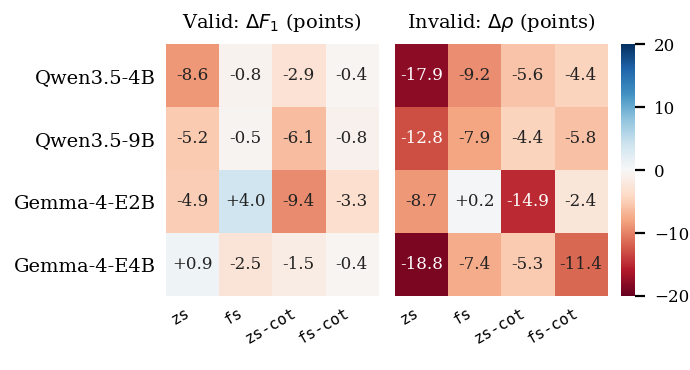

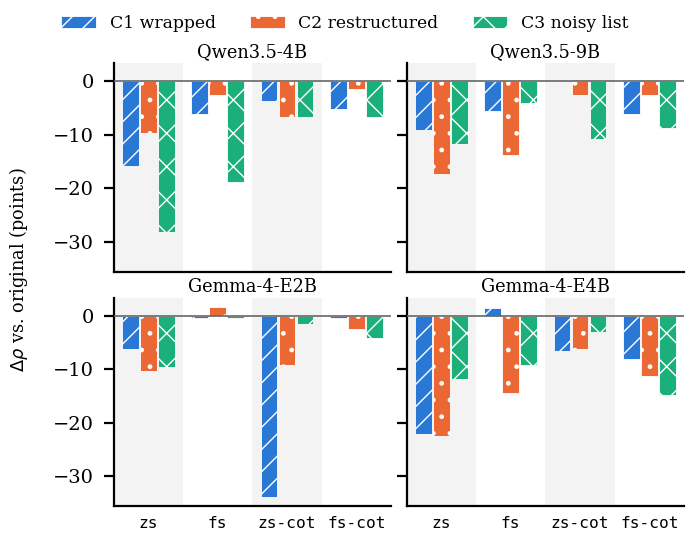

In [2]:
display(Image("figures/fig7_opt_i_change_heatmaps.png", width=440))
display(Image("figures/fig7_opt_v2_invalid_bars.png", width=440))

## Checks against the sentences of Section IV-E
A failed assertion would mean the text and the data disagree.

In [3]:
print("configurations:", len(ov))
assert len(ov) == 16
print("rejection falls in", int((dR < 0).sum()), "of 16; largest drop", round(dR.min(), 1), dR.idxmin())
assert (dR < 0).sum() == 15 and round(dR.min(), 1) == -18.8 and dR.idxmin() == ("Gemma4-E4B", "zs3")
print("F1 falls in", int((dF < 0).sum()), "of 16; largest drop", round(dF.min(), 1), dF.idxmin())
assert (dF < 0).sum() == 14 and round(dF.min(), 1) == -9.4 and dF.idxmin() == ("Gemma4-E2B", "zs3 CoT")
zs = dR.xs("zs3", level="setup")
print("zero-shot rejection change:", zs.round(1).to_dict())
assert round(zs.min(), 1) == -18.8 and round(zs.max(), 1) == -8.7

configurations: 16
rejection falls in 15 of 16; largest drop -18.8 ('Gemma4-E4B', 'zs3')
F1 falls in 14 of 16; largest drop -9.4 ('Gemma4-E2B', 'zs3 CoT')
zero-shot rejection change: {'Qwen3.5-4B': -18.0, 'Qwen3.5-9B': -12.8, 'Gemma4-E2B': -8.7, 'Gemma4-E4B': -18.8}


In [4]:
sel = [(m, s) for m in ("Qwen3.5-4B", "Qwen3.5-9B", "Gemma4-E4B") for s in ("fs3", "fs3 CoT")]
print("fs / fs-cot, Qwen3.5 and Gemma-4-E4B: rejection", round(dR[sel].min(), 1), "to", round(dR[sel].max(), 1), "| F1", round(dF[sel].min(), 1), "to", round(dF[sel].max(), 1))
assert round(dR[sel].min(), 1) == -11.4 and round(dR[sel].max(), 1) == -4.4 and round(dF[sel].min(), 1) == -2.5
both = [k for k in dF.index if dF[k] > 0 and dR[k] > 0]
x = ov.loc[both[0]]
print("gain on both metrics:", both, "| F1", f"{dF[both[0]]:+.1f}", "rejection", f"{dR[both[0]]:+.1f}", "| baseline F1", round(x.F1_base, 2), "rejection", round(x.rej_base, 3))
assert both == [("Gemma4-E2B", "fs3")] and round(dF[both[0]], 1) == 4.0 and round(dR[both[0]], 1) == 0.2 and round(x.rej_base, 3) == 0.015

fs / fs-cot, Qwen3.5 and Gemma-4-E4B: rejection -11.4 to -4.4 | F1 -2.5 to -0.4
gain on both metrics: [('Gemma4-E2B', 'fs3')] | F1 +4.0 rejection +0.2 | baseline F1 0.61 rejection 0.015


In [5]:
h8 = pd.read_csv(RES / "H-08_per_model_and_setup_all_intents.csv", index_col=0)
h8 = h8[h8.model != "mean of 4 models"].set_index(["model", "setup"])      # the 16 configurations (the file also holds mean rows)
fall = {v: int(((h8[f"rejection {v}"] - h8["rejection base"]) < 0).sum()) for v in ("C1", "C2", "C3")}
print("rejection falls under C1, C2, C3 in", fall, "of 16 configurations")
assert fall == {"C1": 14, "C2": 15, "C3": 16}
d = 100 * (h8["rejection C1"] - h8["rejection base"])
print("largest single drop:", round(d.min(), 1), d.idxmin(), "| rejection", round(h8.loc[d.idxmin(), "rejection base"], 2), "->", round(h8.loc[d.idxmin(), "rejection C1"], 2))
assert round(d.min(), 1) == -33.9 and d.idxmin() == ("Gemma4-E2B", "zs3 CoT")

rejection falls under C1, C2, C3 in {'C1': 14, 'C2': 15, 'C3': 16} of 16 configurations
largest single drop: -33.9 ('Gemma4-E2B', 'zs3 CoT') | rejection 0.64 -> 0.3


In [6]:
cat = pd.read_csv(RES / "rq5_rejection_by_category_716.csv", index_col="category")
display(cat.round(3))
# C2 and C3 hide contradictions (rejection of conflicting intents falls); C1 makes broken fragments read like normal requests (malformed falls most)
assert cat.loc["conflicting", "C2"] < cat.loc["conflicting", "V0"] and cat.loc["conflicting", "C3"] < cat.loc["conflicting", "V0"] and cat.loc["conflicting", "C1"] >= cat.loc["conflicting", "V0"]
assert (cat.loc["malformed", "C1"] - cat.loc["malformed", "V0"]) == min(cat.loc[c, "C1"] - cat.loc[c, "V0"] for c in cat.index)
hl = pd.read_csv(RES / "H-05_pooled_headline.csv", index_col=0)
display(hl.iloc[:, :7])

,V0,C1,C2,C3
category,,,,
ambiguous,0.741,0.669,0.735,0.742
conflicting,0.709,0.723,0.533,0.494
malformed,0.679,0.466,0.621,0.536
unsupported,0.830,0.739,0.722,0.768


,original,C1,C2,C3,C1 change (points),C2 change (points),C3 change (points)
valid exact match,0.724,0.705,0.700,0.580,-1.871,-2.351,-14.371
valid F1,0.858,0.845,0.847,0.801,-1.326,-1.124,-5.764
invalid rejection,0.743,0.663,0.661,0.649,-8.013,-8.237,-9.423


## The released sample
`../data/robust/robust_benchmark_sample.json` holds 30 rows: 10 intents with their C1, C2 and C3 variants (the full benchmark of 2,148 variants is available on request, see `../data/robust/README.md`).

In [7]:
s = pd.read_json("../data/robust/robust_benchmark_sample.json")
print(len(s), "rows;", s.parent_index.nunique(), "intents;", s.variant_type.value_counts().to_dict(), "| valid:", s[s.validity == "valid"].parent_index.nunique(), "invalid:", s[s.validity == "invalid"].parent_index.nunique())
assert len(s) == 30 and s.parent_index.nunique() == 10 and set(s.variant_type) == {"C1", "C2", "C3"}
assert sorted(s[s.validity == "valid"].drop_duplicates("parent_index").level) == [1, 2, 3, 4, 5]
assert set(s[s.validity == "invalid"].invalid_category) == {"ambiguous", "conflicting", "malformed", "unsupported"}
assert (s.generated_by == "claude-sonnet-5-5").all()

30 rows; 10 intents; {'C1': 10, 'C2': 10, 'C3': 10} | valid: 5 invalid: 5
